# 04 - Análise exploratória e correlações

Comparação entre os ciclos `2024-2025` e `2025-2026` e análise de correlação mensal entre focos de calor, índice RONI e área queimada a partir de `integrado_mensal_{brasil,biomas,estados}.csv`.

## 1. Leitura das tabelas mensais integradas

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

mensal_brasil = pd.read_csv("../dados/integrado_mensal_brasil.csv")
mensal_biomas = pd.read_csv("../dados/integrado_mensal_biomas.csv")
mensal_estados = pd.read_csv("../dados/integrado_mensal_estados.csv")

print("Brasil:", mensal_brasil.shape, "| Biomas:", mensal_biomas.shape, "| Estados:", mensal_estados.shape)
display(mensal_brasil.head())

Brasil: (24, 12) | Biomas: (144, 13) | Estados: (647, 13)


,ano_mes,total_focos,media_dias_sem_chuva,media_precipitacao,media_risco_fogo,media_frp,soma_frp,trimestre,roni,area_queimada_ha,ciclo,fase_enso
0,2024-12,59278,8.758679,0.150247,0.956117,9.405555,557542.5,NDJ,-1.05,1097364.98,2024-2025 (Sem El Niño),La Niña
1,2025-01,17354,5.633283,1.957289,0.512153,8.632650,149811.0,DJF,-1.10,684858.71,2024-2025 (Sem El Niño),La Niña
2,2025-02,11921,4.234796,1.549300,0.413548,8.225854,98060.4,JFM,-0.85,119853.85,2024-2025 (Sem El Niño),La Niña
3,2025-03,13727,6.992424,1.214493,0.539076,8.256626,113338.7,FMA,-0.66,111370.20,2024-2025 (Sem El Niño),La Niña
4,2025-04,7933,4.591958,1.304596,0.530904,6.894996,54698.0,MAM,-0.50,69155.78,2024-2025 (Sem El Niño),La Niña


## 2. Série mensal das três bases (`2024-12` a `2026-10`)

Recortamos até `2026-10` porque `2026-11` tem focos apenas até o dia 18 e ainda não possui área queimada publicada.

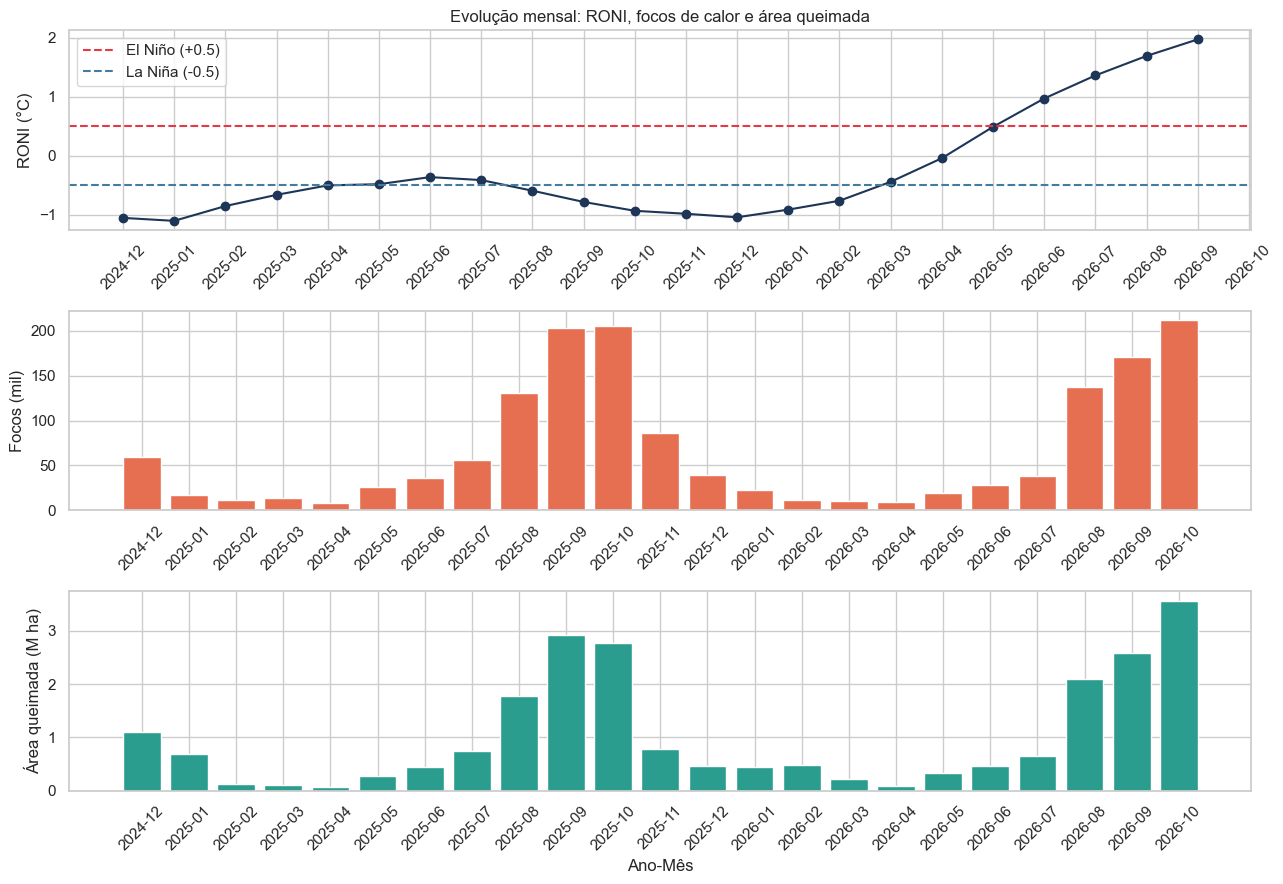

In [2]:
serie = mensal_brasil[mensal_brasil["ano_mes"] <= "2026-10"].copy()

plt.figure(figsize=(13, 9))

plt.subplot(3, 1, 1)
plt.plot(serie["ano_mes"], serie["roni"], marker="o", color="#1d3557")
plt.axhline(0.5, color="#e63946", linestyle="--", label="El Niño (+0.5)")
plt.axhline(-0.5, color="#457b9d", linestyle="--", label="La Niña (-0.5)")
plt.ylabel("RONI (°C)")
plt.title("Evolução mensal: RONI, focos de calor e área queimada")
plt.xticks(rotation=45)
plt.legend(loc="upper left")

plt.subplot(3, 1, 2)
plt.bar(serie["ano_mes"], serie["total_focos"] / 1000, color="#e76f51")
plt.ylabel("Focos (mil)")
plt.xticks(rotation=45)

plt.subplot(3, 1, 3)
plt.bar(serie["ano_mes"], serie["area_queimada_ha"] / 1000000, color="#2a9d8f")
plt.ylabel("Área queimada (M ha)")
plt.xlabel("Ano-Mês")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 3. Comparação por bioma (`Dez-Out`)

total_focos                      \
ciclo          2024-2025 (Sem El Niño) 2025-2026 (El Niño)   
Bioma                                                        
Amazônia                      199284.0            342204.0   
Caatinga                      102723.0             64218.0   
Cerrado                       397709.0            245004.0   
Mata Atlântica                 59000.0             40362.0   
Pampa                           3327.0              1813.0   
Pantanal                        5195.0              4721.0   

                     area_queimada_mha                      
ciclo          2024-2025 (Sem El Niño) 2025-2026 (El Niño)  
Bioma                                                       
Amazônia                          3.99                5.57  
Caatinga                          0.37                0.34  
Cerrado                           6.36                5.07  
Mata Atlântica                    0.21                0.24  
Pampa                             0.01                0.00  
Pantanal                          0.08                0.17

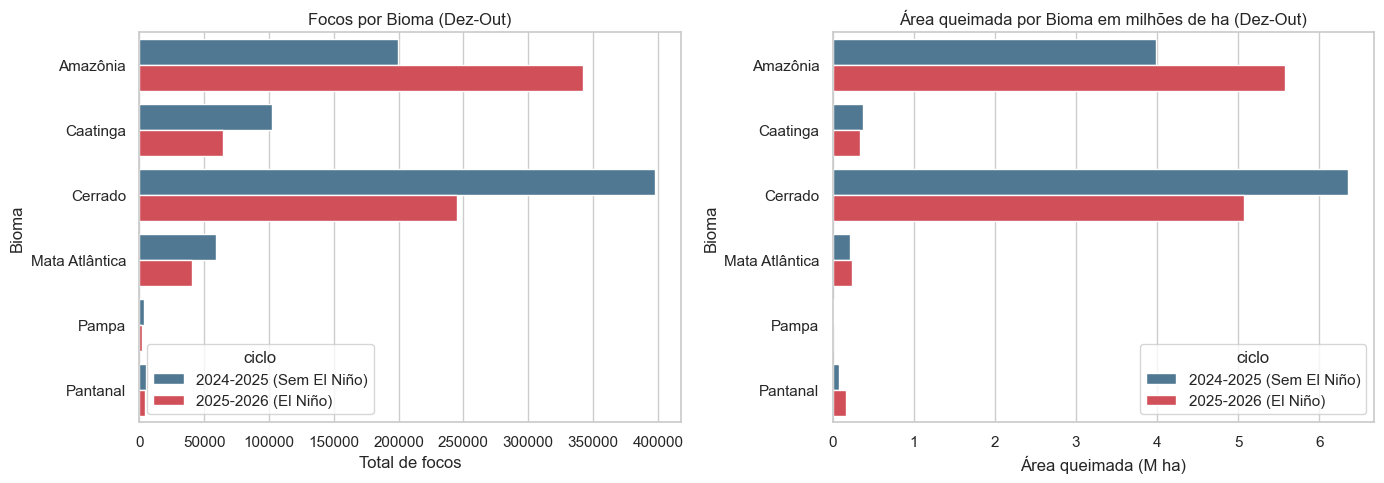

In [3]:
biomas_comp = mensal_biomas[~mensal_biomas["ano_mes"].str.endswith("-11")].copy()
resumo_biomas = biomas_comp.groupby(["Bioma", "ciclo"], as_index=False)[["total_focos", "area_queimada_ha"]].sum()
resumo_biomas["area_queimada_mha"] = resumo_biomas["area_queimada_ha"] / 1000000

display(resumo_biomas.pivot(index="Bioma", columns="ciclo", values=["total_focos", "area_queimada_mha"]).round(2))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(data=resumo_biomas, y="Bioma", x="total_focos", hue="ciclo", palette=["#457b9d", "#e63946"])
plt.title("Focos por Bioma (Dez-Out)")
plt.xlabel("Total de focos")

plt.subplot(1, 2, 2)
sns.barplot(data=resumo_biomas, y="Bioma", x="area_queimada_mha", hue="ciclo", palette=["#457b9d", "#e63946"])
plt.title("Área queimada por Bioma em milhões de ha (Dez-Out)")
plt.xlabel("Área queimada (M ha)")

plt.tight_layout()
plt.show()

## 4. Comparação dos 10 estados com mais focos (`Dez-Out`)

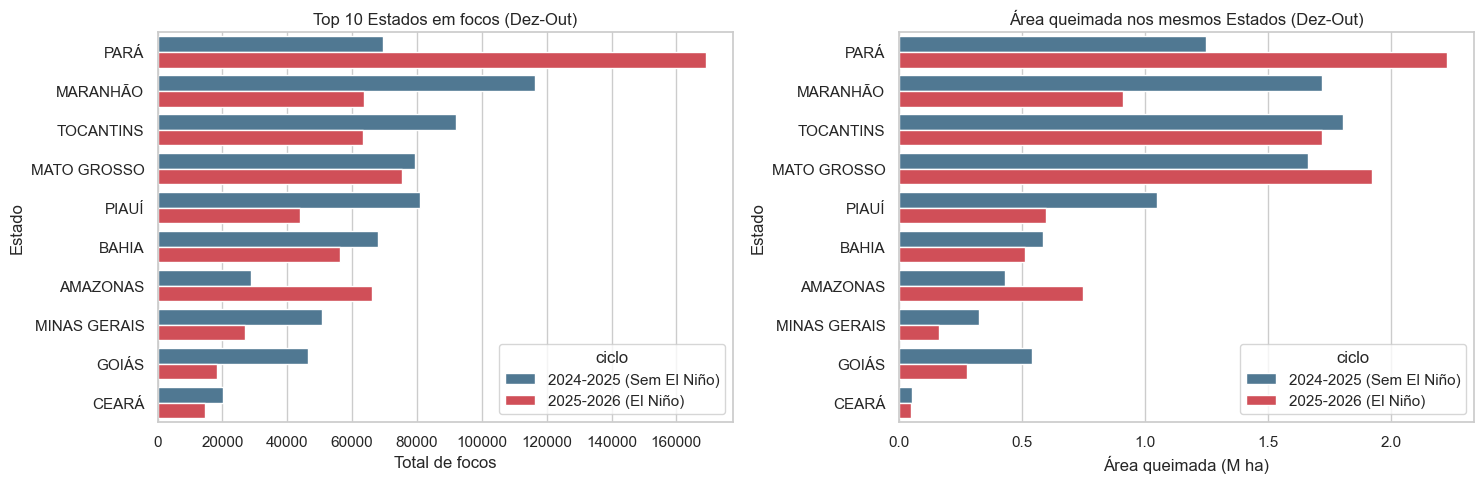

In [4]:
estados_comp = mensal_estados[~mensal_estados["ano_mes"].str.endswith("-11")].copy()

totais_uf = estados_comp.groupby("Estado", as_index=False)["total_focos"].sum()
top10_ufs = list(totais_uf.sort_values("total_focos", ascending=False).head(10)["Estado"])

resumo_ufs = estados_comp[estados_comp["Estado"].isin(top10_ufs)].groupby(
    ["Estado", "ciclo"], as_index=False
)[["total_focos", "area_queimada_ha"]].sum()
resumo_ufs["area_queimada_mha"] = resumo_ufs["area_queimada_ha"] / 1000000

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
sns.barplot(data=resumo_ufs, y="Estado", x="total_focos", hue="ciclo", order=top10_ufs, palette=["#457b9d", "#e63946"])
plt.title("Top 10 Estados em focos (Dez-Out)")
plt.xlabel("Total de focos")

plt.subplot(1, 2, 2)
sns.barplot(data=resumo_ufs, y="Estado", x="area_queimada_mha", hue="ciclo", order=top10_ufs, palette=["#457b9d", "#e63946"])
plt.title("Área queimada nos mesmos Estados (Dez-Out)")
plt.xlabel("Área queimada (M ha)")

plt.tight_layout()
plt.show()

## 5. Correlações mensais no Brasil e por bioma

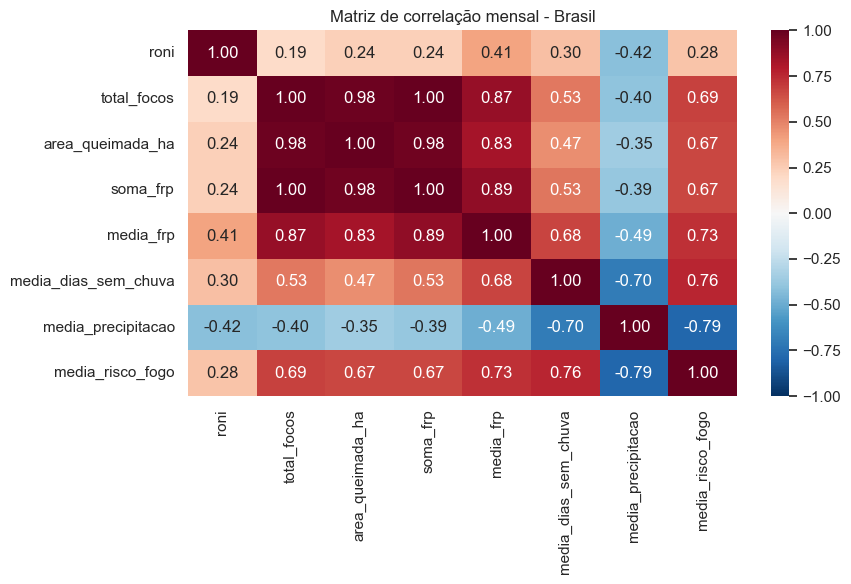

In [5]:
colunas_corr = [
    "roni", "total_focos", "area_queimada_ha", "soma_frp",
    "media_frp", "media_dias_sem_chuva", "media_precipitacao", "media_risco_fogo",
]

plt.figure(figsize=(9, 6))
sns.heatmap(serie[colunas_corr].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Matriz de correlação mensal - Brasil")
plt.tight_layout()
plt.show()

,focos_x_area_ha,soma_frp_x_area_ha,roni_x_focos,roni_x_area_ha
Bioma,,,,
Amazônia,0.895,0.833,0.414,-0.066
Caatinga,0.920,0.934,-0.225,-0.069
Cerrado,0.965,0.981,0.150,0.360
Mata Atlântica,0.805,0.766,-0.023,0.207
Pampa,0.698,0.841,-0.159,-0.171
Pantanal,0.681,0.638,-0.015,0.063


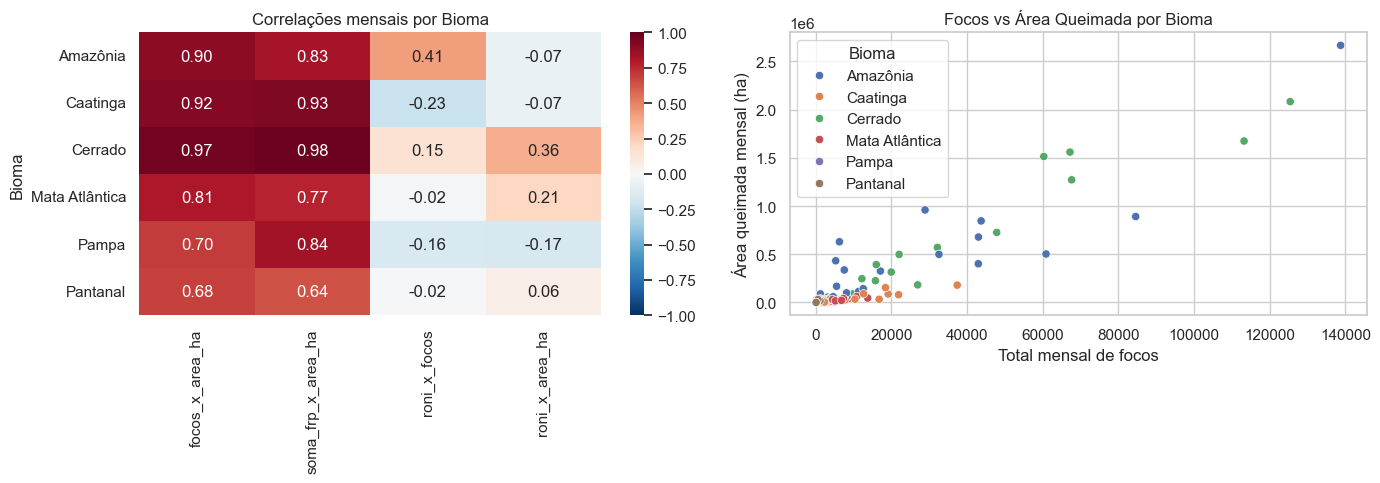

In [6]:
biomas_23m = mensal_biomas[mensal_biomas["ano_mes"] <= "2026-10"].copy()

linhas_corr = []
for bioma in sorted(biomas_23m["Bioma"].unique()):
     sub = biomas_23m[biomas_23m["Bioma"] == bioma]
     linhas_corr.append({
         "Bioma": bioma,
         "focos_x_area_ha": sub["total_focos"].corr(sub["area_queimada_ha"]),
         "soma_frp_x_area_ha": sub["soma_frp"].corr(sub["area_queimada_ha"]),
         "roni_x_focos": sub["roni"].corr(sub["total_focos"]),
         "roni_x_area_ha": sub["roni"].corr(sub["area_queimada_ha"]),
     })

df_corr_biomas = pd.DataFrame(linhas_corr).set_index("Bioma")
display(df_corr_biomas.round(3))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.heatmap(df_corr_biomas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlações mensais por Bioma")

plt.subplot(1, 2, 2)
sns.scatterplot(data=biomas_23m, x="total_focos", y="area_queimada_ha", hue="Bioma")
plt.title("Focos vs Área Queimada por Bioma")
plt.xlabel("Total mensal de focos")
plt.ylabel("Área queimada mensal (ha)")

plt.tight_layout()
plt.show()

## 6. Síntese da análise

Entre dezembro de 2024 e outubro de 2026, o total mensal de focos e a área queimada tiveram correlação `r = 0,98` no Brasil (`r = 0,98` também com `soma_frp` e `r = 0,83` com `media_frp`). No mesmo intervalo, `media_dias_sem_chuva` teve correlação `r = 0,76` com `media_risco_fogo`.

Na série nacional agregada, `roni` e total de focos ficaram em `r = 0,19` porque o El Niño produz efeitos opostos entre as regiões. Separando por bioma, a Amazônia apresentou correlação positiva (`r = 0,41`), subiu `75,2%` em focos no ciclo completo e atingiu `2,67 milhões de ha` queimados em outubro de 2026, ante `846 mil ha` em outubro de 2025, puxada por Pará e Amazonas. Em sentido contrário, Caatinga (`r = -0,23`) e Pampa (`r = -0,16`, queda de `46,5%` nos focos) registraram recuo.

Nas séries utilizadas, `roni.csv` vai até `2026-09`, a área queimada até `2026-10` e os focos até `18/11/2026`.